In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Loading
train = pd.read_csv('aug_train.csv')
test = pd.read_csv('aug_test.csv')

In [2]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  str    
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  str    
 4   relevent_experience     19158 non-null  str    
 5   enrolled_university     18772 non-null  str    
 6   education_level         18698 non-null  str    
 7   major_discipline        16345 non-null  str    
 8   experience              19093 non-null  str    
 9   company_size            13220 non-null  str    
 10  company_type            13018 non-null  str    
 11  last_new_job            18735 non-null  str    
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), str(10)
memory usage: 2.

In [3]:
train.describe(include="all")

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
count,19158.000000,19158,19158.000000,14650,19158,18772,18698,16345,19093,13220,13018,18735,19158.000000,19158.000000
unique,NaN,123,NaN,3,2,3,5,6,22,8,6,6,NaN,NaN
top,NaN,city_103,NaN,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,1,NaN,NaN
freq,NaN,4355,NaN,13221,13792,13817,11598,14492,3286,3083,9817,8040,NaN,NaN
mean,16875.358179,NaN,0.828848,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.366896,0.249348
std,9616.292592,NaN,0.123362,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.058462,0.432647
min,1.000000,NaN,0.448000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000
25%,8554.250000,NaN,0.740000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.000000,0.000000
50%,16982.500000,NaN,0.903000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.000000,0.000000
75%,25169.750000,NaN,0.920000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,88.000000,0.000000


In [4]:
# Tampilkan kolom-kolom yang memiliki nilai kosong
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

gender                 4508
enrolled_university     386
education_level         460
major_discipline       2813
experience               65
company_size           5938
company_type           6140
last_new_job            423
dtype: int64

In [5]:
# Memastikan enrollee_id tidak ada yang duplikat untuk pertimbangan fitur
df = pd.DataFrame(train)
duplicated_rows = df[df.duplicated(subset=['enrollee_id'], keep=False)]
print("Rows with duplicates:")
print(duplicated_rows)

Rows with duplicates:
Empty DataFrame
Columns: [enrollee_id, city, city_development_index, gender, relevent_experience, enrolled_university, education_level, major_discipline, experience, company_size, company_type, last_new_job, training_hours, target]
Index: []


In [6]:
# Drop kolom enrollee_id pada dataframe baru karena tidak mempengaruhi fitur untuk prediksi, hanya sebagai tracking ID
df = train.drop(columns = "enrollee_id")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city                    19158 non-null  str    
 1   city_development_index  19158 non-null  float64
 2   gender                  14650 non-null  str    
 3   relevent_experience     19158 non-null  str    
 4   enrolled_university     18772 non-null  str    
 5   education_level         18698 non-null  str    
 6   major_discipline        16345 non-null  str    
 7   experience              19093 non-null  str    
 8   company_size            13220 non-null  str    
 9   company_type            13018 non-null  str    
 10  last_new_job            18735 non-null  str    
 11  training_hours          19158 non-null  int64  
 12  target                  19158 non-null  float64
dtypes: float64(2), int64(1), str(10)
memory usage: 1.9 MB


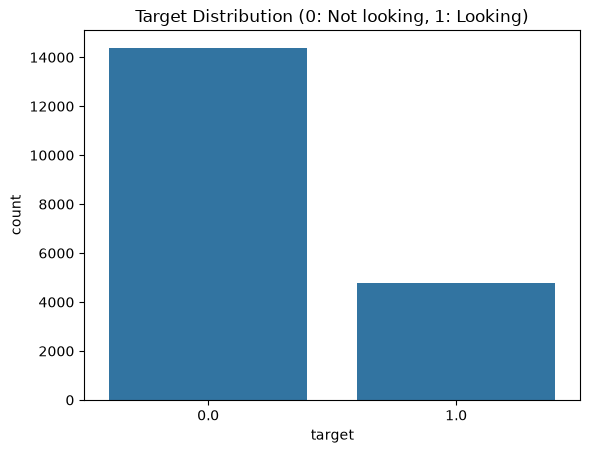

In [7]:
# Exploratory Data Analysis Phase
# Check target distribution
sns.countplot(x='target', data=df)
plt.title('Target Distribution (0: Not looking, 1: Looking)')
plt.show()

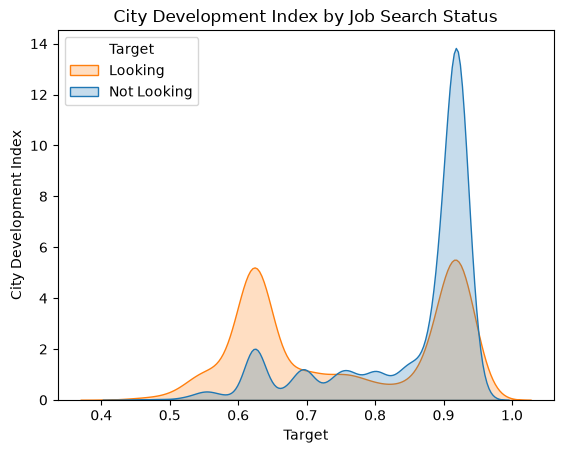

In [8]:
# Check city_development_index distribution against target
sns.kdeplot(
    data=df,
    x='city_development_index',
    hue='target',
    fill=True,
    common_norm=False
)
plt.title("City Development Index by Job Search Status")
plt.xlabel("Target")
plt.ylabel("City Development Index")
plt.legend(title="Target", labels=["Looking", "Not Looking"])
plt.show()

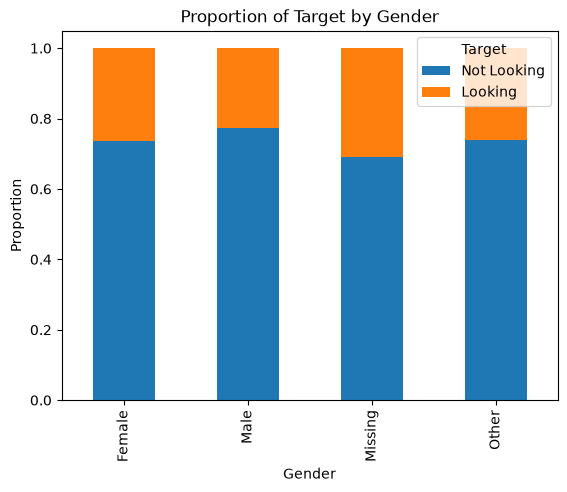

In [9]:
# Check gender distribution against target by proportion, including missing gender
gender = df["gender"].fillna("Missing")

pd.crosstab(gender, df["target"], normalize="index").plot(
    kind="bar",
    stacked=True
)

plt.title("Proportion of Target by Gender")
plt.ylabel("Proportion")
plt.xlabel("Gender")
plt.legend(title="Target", labels=["Not Looking", "Looking"])
plt.show()

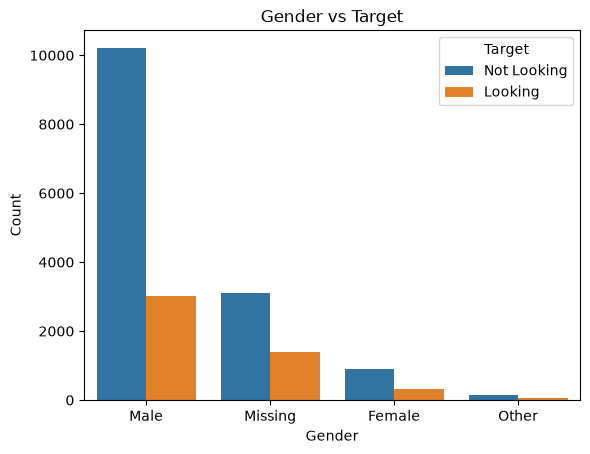

In [10]:
# Check gender distribution against target by count, including missing ones
df["gender_plot"] = df["gender"].fillna("Missing")

sns.countplot(data=df, x="gender_plot", hue="target")

plt.title("Gender vs Target")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.legend(title="Target", labels=["Not Looking", "Looking"])
plt.show()

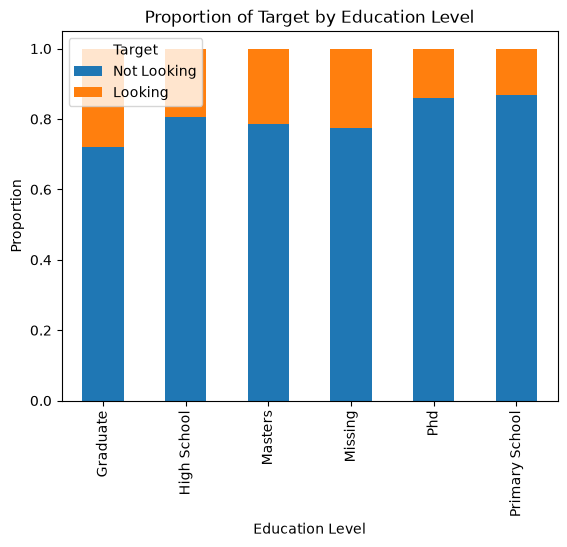

In [11]:
# Check education_level distribution by proportion, including the missing ones
edu_level = df["education_level"].fillna("Missing")

pd.crosstab(edu_level, df["target"], normalize="index").plot(
    kind="bar",
    stacked=True
)

plt.title("Proportion of Target by Education Level")
plt.ylabel("Proportion")
plt.xlabel("Education Level")
plt.legend(title="Target", labels=["Not Looking", "Looking"])
plt.show()

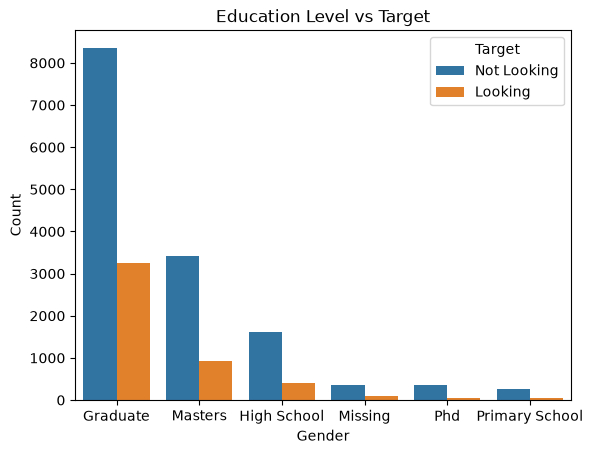

In [12]:
# Check education_level distribution against target by count, including missing ones
df["edulevel_plot"] = df["education_level"].fillna("Missing")

sns.countplot(data=df, x="edulevel_plot", hue="target")

plt.title("Education Level vs Target")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.legend(title="Target", labels=["Not Looking", "Looking"])
plt.show()

In [13]:
# Data Cleaning
df_cleaning = pd.DataFrame(df)
# Penanganan missing values pada fitur gender yang missing
df_cleaning = df_cleaning.drop(columns="gender")
df_cleaning.info()

# Gender ini sangat sensitif untuk digunakan sebagai fitur prediksi, bisa juga membuat bias terhadap gender

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city                    19158 non-null  str    
 1   city_development_index  19158 non-null  float64
 2   relevent_experience     19158 non-null  str    
 3   enrolled_university     18772 non-null  str    
 4   education_level         18698 non-null  str    
 5   major_discipline        16345 non-null  str    
 6   experience              19093 non-null  str    
 7   company_size            13220 non-null  str    
 8   company_type            13018 non-null  str    
 9   last_new_job            18735 non-null  str    
 10  training_hours          19158 non-null  int64  
 11  target                  19158 non-null  float64
 12  gender_plot             19158 non-null  str    
 13  edulevel_plot           19158 non-null  str    
dtypes: float64(2), int64(1), str(11)
memory usage: 2.

In [14]:
# Drop kolom bekas penggunaan untuk EDA
df_cleaning = df_cleaning.drop(columns="gender_plot")
df_cleaning = df_cleaning.drop(columns="edulevel_plot")
df_cleaning.info()

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city                    19158 non-null  str    
 1   city_development_index  19158 non-null  float64
 2   relevent_experience     19158 non-null  str    
 3   enrolled_university     18772 non-null  str    
 4   education_level         18698 non-null  str    
 5   major_discipline        16345 non-null  str    
 6   experience              19093 non-null  str    
 7   company_size            13220 non-null  str    
 8   company_type            13018 non-null  str    
 9   last_new_job            18735 non-null  str    
 10  training_hours          19158 non-null  int64  
 11  target                  19158 non-null  float64
dtypes: float64(2), int64(1), str(9)
memory usage: 1.8 MB


In [15]:
# Penanganan missing values pada fitur-fitur yang missing, diberikan label Unknown karena ada beberapa faktor yang bisa dijadikan pertimbangan
categorical_fill_unknown = [
    "enrolled_university",
    "education_level",
    "major_discipline",
    "company_size",
    "company_type",
    "last_new_job"
]

for col in categorical_fill_unknown:
    df_cleaning[col] = df_cleaning[col].fillna("Unknown")

In [16]:
# Memastikan penanganan missing values pada fitur-fitur di atas sudah terjadi
for col in categorical_fill_unknown:
    print(f"{col} : {df_cleaning[col].isnull().sum()}")

enrolled_university : 0
education_level : 0
major_discipline : 0
company_size : 0
company_type : 0
last_new_job : 0


In [17]:
# Penanganan missing values pada fitur experience
# Melihat nilai apa saja dalam fitur experience
print(df_cleaning["experience"].unique())

<StringArray>
['>20',  '15',   '5',  '<1',  '11',  '13',   '7',  '17',   '2',  '16',   '1',
   '4',  '10',  '14',  '18',  '19',  '12',   '3',   '6',   '9',   '8',  '20',
   nan]
Length: 23, dtype: str


In [18]:
# Buat kolom yang menandakan fitur experience sebagai missing
df_cleaning["experience_missing"] = df_cleaning["experience"].isna().astype(int)

# Ubah fitur experience menjadi numerical feature
df_cleaning["experience"] = (
    df_cleaning["experience"]
    .replace({
        ">20": 20.5,
        "15": 15,
        "5": 5,
        "<1": 0.5,
        "11": 11,
        "13": 13,
        "7": 7,
        "17": 17,
        "2": 2,
        "16": 16,
        "1": 1,
        "4": 4,
        "10": 10,
        "14": 14,
        "18": 18,
        "19": 19,
        "12": 12,
        "3": 3,
        "6": 6,
        "9": 9,
        "8": 8,
        "20": 20,
    })
    .astype(float)
)

# Isi missing value dengan median fitur experience
df_cleaning["experience"] = df_cleaning["experience"].fillna(df_cleaning["experience"].median())

In [19]:
# Memastikan fitur experience sudah diubah menjadi numerical feature
print(df_cleaning["experience"].unique())

[20.5 15.   5.   0.5 11.  13.   7.  17.   2.  16.   1.   4.  10.  14.
 18.  19.  12.   3.   6.   9.   8.  20. ]


In [20]:
# Memastikan fitur experience tidak ada yang kosong
print(f"Jumlah kolom experience yang kosong : {df_cleaning["experience"].isnull().sum()}")

Jumlah kolom experience yang kosong : 0


In [21]:
# Data Transformation
df_transform = pd.DataFrame(df_cleaning)
df_transform.info()


<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city                    19158 non-null  str    
 1   city_development_index  19158 non-null  float64
 2   relevent_experience     19158 non-null  str    
 3   enrolled_university     19158 non-null  str    
 4   education_level         19158 non-null  str    
 5   major_discipline        19158 non-null  str    
 6   experience              19158 non-null  float64
 7   company_size            19158 non-null  str    
 8   company_type            19158 non-null  str    
 9   last_new_job            19158 non-null  str    
 10  training_hours          19158 non-null  int64  
 11  target                  19158 non-null  float64
 12  experience_missing      19158 non-null  int64  
dtypes: float64(3), int64(2), str(8)
memory usage: 1.9 MB


In [22]:
# Persiapan Binary Encoding dengan melihat unique values di fitur relevent_experience
print(f"relevent_experience : {df_transform["relevent_experience"].unique()}")

relevent_experience : <StringArray>
['Has relevent experience', 'No relevent experience']
Length: 2, dtype: str


In [23]:
# Melakukan Binary Encoding
relevant_exp_map = {
    "Has relevent experience": 1,
    "No relevent experience": 0
}

# Mapping ke Binary Encoding yang telah dibuat
df_transform["relevent_experience"] = df_transform["relevent_experience"].map(relevant_exp_map)

In [24]:
# Persiapan Ordinal Encoding dengan melihat unique values di setiap fitur
init_unique_ord_enc = [
    "enrolled_university",
    "education_level",
    "company_size",
    "last_new_job"
]

for col in init_unique_ord_enc:
    print(f"{col} : {df_transform[col].unique()}")

enrolled_university : <StringArray>
['no_enrollment', 'Full time course', 'Unknown', 'Part time course']
Length: 4, dtype: str
education_level : <StringArray>
['Graduate', 'Masters', 'High School', 'Unknown', 'Phd', 'Primary School']
Length: 6, dtype: str
company_size : <StringArray>
[  'Unknown',     '50-99',       '<10',    '10000+', '5000-9999', '1000-4999',
     '10/49',   '100-500',   '500-999']
Length: 9, dtype: str
last_new_job : <StringArray>
['1', '>4', 'never', '4', '3', '2', 'Unknown']
Length: 7, dtype: str


In [25]:
# Melakukan Ordinal Encoding ke beberapa fitur berikut:
education_map = {
    "Primary School": 0,
    "High School": 1,
    "Graduate": 2,
    "Masters": 3,
    "Phd": 4,
    "Unknown": -1
}

enrolled_map = {
    "no_enrollment": 0,
    "Part time course": 1,
    "Full time course": 2,
    "Unknown": -1
}

company_size_map = {
    "<10": 0,
    "10/49": 1,
    "50-99": 2,
    "100-500": 3,
    "500-999": 4,
    "1000-4999": 5,
    "5000-9999": 6,
    "10000+": 7,
    "Unknown": -1
}

# Mapping fitur ke Ordinal Encoding yang telah dibuat
df_transform["education_level"] = df_transform["education_level"].map(education_map)
df_transform["enrolled_university"] = df_transform["enrolled_university"].map(enrolled_map)
df_transform["company_size"] = df_transform["company_size"].map(company_size_map)

In [26]:
# Buat flagging untuk never dan Unknown di fitur last_new_job
df_transform["last_new_job_never"] = (df_transform["last_new_job"] == "never").astype(int)
df_transform["last_new_job_unknown"] = (df_transform["last_new_job"] == "Unknown").astype(int)

# Ordinal Encoding
last_new_job_map = {
    "never": 0,
    "1": 1,
    "2": 2,
    "3": 3,
    "4": 4,
    ">4": 5,
    "Unknown": -1
}

# Mapping ke Ordinal Encoding yang telah dibuat
df_transform["last_new_job"] = df_transform["last_new_job"].map(last_new_job_map)

In [27]:
# Persiapan One-Hot Encoding dengan melihat unique values di setiap fitur
init_unique_oh_enc = [
    "company_type",
    "major_discipline"
]

for col in init_unique_oh_enc:
    print(f"{col} : {df_transform[col].unique()}")

company_type : <StringArray>
[            'Unknown',             'Pvt Ltd',      'Funded Startup',
 'Early Stage Startup',               'Other',       'Public Sector',
                 'NGO']
Length: 7, dtype: str
major_discipline : <StringArray>
['STEM', 'Business Degree', 'Unknown', 'Arts', 'Humanities', 'No Major',
 'Other']
Length: 7, dtype: str


In [28]:
# Melakukan One-Hot Encoding
df_transform = pd.get_dummies(df_transform, columns = ["company_type"])
df_transform = pd.get_dummies(df_transform, columns = ["major_discipline"])

In [29]:
# Drop fitur City, dikarenakan sudah ada city_development_index yang memiliki arti
df_transform = df_transform.drop(columns = "city")

In [30]:
# Data Modelling
df_model = pd.DataFrame(df_transform)
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 26 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   city_development_index            19158 non-null  float64
 1   relevent_experience               19158 non-null  int64  
 2   enrolled_university               19158 non-null  int64  
 3   education_level                   19158 non-null  int64  
 4   experience                        19158 non-null  float64
 5   company_size                      19158 non-null  int64  
 6   last_new_job                      19158 non-null  int64  
 7   training_hours                    19158 non-null  int64  
 8   target                            19158 non-null  float64
 9   experience_missing                19158 non-null  int64  
 10  last_new_job_never                19158 non-null  int64  
 11  last_new_job_unknown              19158 non-null  int64  
 12  company_type_Ea

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Pemisahan fitur (X) dan target (X)
X = df_model.drop(columns=['target'])
y = df_model['target']

# Konversi kolom dengan tipe data bool ke int
bool_cols = X.select_dtypes(include=["bool"]).columns
X[bool_cols] = X[bool_cols].astype(int)

# Check target distribution
print(y.value_counts())
print(y.value_counts(normalize=True))

# Membagi dataset menjadi training dan testing
# Stratified split memastikan rasio antara 0 and 1 dalam training sama dengan data original
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y
)

target
0.0    14381
1.0     4777
Name: count, dtype: int64
target
0.0    0.750652
1.0    0.249348
Name: proportion, dtype: float64


In [32]:
# Check proportion after splitting
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

target
0.0    0.75062
1.0    0.24938
Name: proportion, dtype: float64
target
0.0    0.750783
1.0    0.249217
Name: proportion, dtype: float64


In [33]:
# Menghitung panjang/jumlah data
print("Jumlah data: ", len(X))
# Menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(X_train))
# Menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(X_test))

Jumlah data:  19158
Jumlah data latih:  15326
Jumlah data test:  3832


In [34]:
from sklearn.ensemble import RandomForestClassifier

# Melatih model dengan RandomForestClassifier tanpa class_weight = "balanced"
# Konfigurasi RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators = 300,
    min_samples_leaf = 5,
    random_state = 42,
    n_jobs = -1
)

# Melatih model dengan RandomForestClassifier dengan class_weight = "balanced"
# Konfigurasi RandomForestClassifier
rf_balanced = RandomForestClassifier(
    n_estimators = 300,
    min_samples_leaf = 5,
    class_weight = "balanced",
    random_state = 42,
    n_jobs = -1
)

# Latih model dengan data
rf.fit(X_train, y_train)
rf_balanced.fit(X_train, y_train)

# Dikarenakan data merupakan imbalanced maka metric accuracy tidak berguna disini, oleh karena itu, kita gunakan ROC-AUC sebagai metric
rf_proba = rf.predict_proba(X_test)[:, 1]
rf_balanced_proba = rf_balanced.predict_proba(X_test)[:, 1]

print("RandomForest ROC-AUC:", roc_auc_score(y_test, rf_proba))
print("RandomForest Balanced ROC-AUC:", roc_auc_score(y_test, rf_balanced_proba))

RandomForest ROC-AUC: 0.8134738956919565
RandomForest Balanced ROC-AUC: 0.8149046326980365


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Melatih model dengan Logistic Regression tanpa class_weight = "balanced"
# Konfigurasi Logistic Regression dengan StandardScaler() untuk scaling fitur
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter = 2000,
        random_state = 42
    )
)

# Melatih model dengan Logistic Regression dengan class_weight = "balanced"
# Konfigurasi Logistic Regression dengan StandardScaler() untuk scaling fitur
log_reg_balanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter = 2000,
        class_weight = "balanced",
        random_state = 42
    )
)

# Latih Model dengan Data
log_reg.fit(X_train, y_train)
log_reg_balanced.fit(X_train, y_train)

log_proba = log_reg.predict_proba(X_test)[:, 1]
log_balanced_proba = log_reg_balanced.predict_proba(X_test)[:, 1]

print("Logistic Regression ROC-AUC:", roc_auc_score(y_test, log_proba))
print("Logistic Regression Balanced ROC-AUC:", roc_auc_score(y_test, log_balanced_proba))

Logistic Regression ROC-AUC: 0.7834599013297374
Logistic Regression Balanced ROC-AUC: 0.7843290440340159


In [36]:
from lightgbm import LGBMClassifier
# Melatih model dengan LGBMClassifier
# Konfigurasi LGBMClassifier
lgbm = LGBMClassifier(
    n_estimators = 500,
    learning_rate = 0.05,
    subsample = 0.9,
    colsample_bytree = 0.9,
    random_state = 42,
    n_jobs = -1,
    verbose = -1
)

# Melatih model dengan LGBMClassifier dengan opsi is_unbalance = True
# Konfigurasi LGBMClassifier
lgbm_balanced = LGBMClassifier(
    n_estimators = 500,
    learning_rate = 0.05,
    subsample = 0.9,
    colsample_bytree = 0.9,
    is_unbalance = True,
    random_state = 42,
    n_jobs = -1,
    verbose = -1
)

# Latih Model dengan Data
lgbm.fit(X_train, y_train)
lgbm_balanced.fit(X_train, y_train)

lgbm_proba = lgbm.predict_proba(X_test)[:, 1]
lgbm_balanced_proba = lgbm_balanced.predict_proba(X_test)[:, 1]

print("LGBM ROC-AUC:", roc_auc_score(y_test, lgbm_proba))
print("LGBM Balanced ROC-AUC:", roc_auc_score(y_test, lgbm_balanced_proba))


LGBM ROC-AUC: 0.8144385785804367
LGBM Balanced ROC-AUC: 0.8147717863466707


In [37]:
# Cross Validation Score antar model
from sklearn.model_selection import cross_val_score

models = {
    "RF": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),

    "RF_balanced": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "LogReg": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    ),

    "LogReg_balanced": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    ),
    
    "LGBM": LGBMClassifier(
        n_estimators = 500,
        learning_rate = 0.05,
        subsample = 0.9,
        colsample_bytree = 0.9,
        random_state = 42,
        n_jobs = -1,
        verbose = -1
    ),
    
    "LGBM_balanced": LGBMClassifier(
        n_estimators = 500,
        learning_rate = 0.05,
        subsample = 0.9,
        colsample_bytree = 0.9,
        is_unbalance = True,
        random_state = 42,
        n_jobs = -1,
        verbose = -1
    )
}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv = 5,
        scoring = "roc_auc"
    )

    print(f"{name}: CV ROC-AUC = {scores.mean():.4f} +/- {scores.std():.4f}")

RF: CV ROC-AUC = 0.7994 +/- 0.0081
RF_balanced: CV ROC-AUC = 0.7995 +/- 0.0073
LogReg: CV ROC-AUC = 0.7721 +/- 0.0066
LogReg_balanced: CV ROC-AUC = 0.7723 +/- 0.0066
LGBM: CV ROC-AUC = 0.7918 +/- 0.0085
LGBM_balanced: CV ROC-AUC = 0.7921 +/- 0.0090
